# Project 2: Housing Price Prediction – Pass 03

## Problem Definition


State the business problem. Translate the business problem into a Data Science problem by stating what kind of problem it is ( supervised vs unsupervised ) and whether it is a classification, regression, or clustering problem.

Statement:

We want to predict housing sale prices based on various correlated feature data. This is a *supervised regression* problem, where the target of the prediction is sales prices. To accomplish this, we use a regression model alongside Regression prediction techniques, as well as feature scaling and regularization to minimize the RMS percentage error.

## Data Collection/Sources


Data Collection describes the process by which we obtain the data for use in the project. In this case, our data comes from S3 storage buckets on AWS, which we load into memory (variables) via URLs by passing them to the read_csv function of the pandas python library (more on that soon).

The data comes in one large set containing the full data available for use in the project. It is supplemented by a data dictionary that describes the set, the data types of the included data, and other information relevant to its use.

Finally, to store the data in a form we can work with in memory, we use a storage structure called a DataFrame object from the pandas python library. This object allows us to quickly view the data and preview operations on the data without changing it, as well as make updates to the data in a highly intuitive way.

First, load Pandas, Numpy, and Matplotlib modules:

In [440]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets, metrics

Load data Train.csv from AWS S3:

In [441]:
# url
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv'

Next, make a preview DataFrame to look at columns:

In [442]:
# make preview
df_preview = pd.read_csv(url, nrows=1)
df_preview

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,905101070,20,RL,62.0,14299,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,7,2007,WD,Normal,115400


In [443]:
# preview all column names
df_preview.columns

Index(['PID', 'MS SubClass', 'MS Zoning', 'Lot Frontage', 'Lot Area', 'Street',
       'Alley', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config',
       'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type',
       'House Style', 'Overall Qual', 'Overall Cond', 'Year Built',
       'Year Remod/Add', 'Roof Style', 'Roof Matl', 'Exterior 1st',
       'Exterior 2nd', 'Mas Vnr Type', 'Mas Vnr Area', 'Exter Qual',
       'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure',
       'BsmtFin Type 1', 'BsmtFin SF 1', 'BsmtFin Type 2', 'BsmtFin SF 2',
       'Bsmt Unf SF', 'Total Bsmt SF', 'Heating', 'Heating QC', 'Central Air',
       'Electrical', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF',
       'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath',
       'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'Kitchen Qual',
       'TotRms AbvGrd', 'Functional', 'Fireplaces', 'Fireplace Qu',
       'Garage Type', 'Garage Yr Blt', 'Garage Finish'

Define the target column (and features types, if required):

In [444]:
# define target column (by name) and target features type
target_col = "SalePrice"
feature_types = ["int64"]

Create list of target col and feature cols:

In [445]:
# use list comprehension to generate list of target col + selected feature cols
selected_cols = [
    col
    for col in df_preview.columns
    if col == target_col or df_preview[col].dtype in feature_types
]
selected_cols

['PID',
 'MS SubClass',
 'Lot Area',
 'Overall Qual',
 'Overall Cond',
 'Year Built',
 'Year Remod/Add',
 '1st Flr SF',
 '2nd Flr SF',
 'Low Qual Fin SF',
 'Gr Liv Area',
 'Full Bath',
 'Half Bath',
 'Bedroom AbvGr',
 'Kitchen AbvGr',
 'TotRms AbvGrd',
 'Fireplaces',
 'Wood Deck SF',
 'Open Porch SF',
 'Enclosed Porch',
 '3Ssn Porch',
 'Screen Porch',
 'Pool Area',
 'Misc Val',
 'Mo Sold',
 'Yr Sold',
 'SalePrice']

Read in the data from .csv using target_col and feature_types:

In [446]:
# make dataframe
df = pd.read_csv( url, usecols=selected_cols )

Finally, check the dataframe:

In [447]:
# check dataframe
df

,PID,MS SubClass,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,1st Flr SF,2nd Flr SF,Low Qual Fin SF,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
0,905101070,20,14299,4,3,1964,1964,1005,0,0,...,0,0,0,0,0,0,0,7,2007,115400
1,905101330,90,10791,4,5,1967,1967,1296,0,0,...,0,0,0,0,0,0,500,10,2006,90000
2,903454090,50,9000,6,6,1937,1950,780,595,0,...,0,162,0,0,126,0,0,12,2007,141000
3,533244030,60,7379,8,5,2000,2000,975,873,0,...,280,184,0,0,0,0,0,4,2010,254000
4,909252020,70,7200,7,9,1936,2007,575,560,0,...,256,0,0,0,0,0,0,4,2009,155000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,903231070,50,6240,6,6,1934,1950,816,0,360,...,112,0,0,0,0,0,400,9,2006,114500
2633,906201021,80,10778,7,6,1990,1991,1061,0,0,...,114,36,0,0,0,0,0,7,2009,162000
2634,533253070,120,3782,8,5,1981,1981,1226,0,0,...,133,78,0,0,0,0,0,9,2009,211500
2635,527376100,20,10140,6,5,1974,1974,1350,0,0,...,0,0,0,0,0,0,0,8,2009,165000


## Data Cleaning


Data Cleaning is the process of preparing the data set for use in analysis. Many data sets contain bad or null (empty) values, which can cause errors when trying to work with the data and use it in code. Cleaning the data involves removing bad (null-containing) columns and/or rows from the set, as well as imputing (replacing via insertion) similar data into fields with missing or unusable values.

Here, to clean the data, we mostly use the pandas drop function included with pandas DataFrame objects, which allow us to drop columns and rows according to conditions we specify, much like SQL WHERE clauses.

#### 4. Examine the data using tools we have used in class. You should be identifying the various columns such as ...

    - target column
    - feature columns
    - identifier columns
    - null columns
    - null rows

    Tools you should be using include, but are not limited to:

    - head
    - tail
    - shape
    - size
    - info
    - describe
    - nunique
    - unique
    - isnull/isna



- head

In [448]:
# head
df.head()

,PID,MS SubClass,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,1st Flr SF,2nd Flr SF,Low Qual Fin SF,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
0,905101070,20,14299,4,3,1964,1964,1005,0,0,...,0,0,0,0,0,0,0,7,2007,115400
1,905101330,90,10791,4,5,1967,1967,1296,0,0,...,0,0,0,0,0,0,500,10,2006,90000
2,903454090,50,9000,6,6,1937,1950,780,595,0,...,0,162,0,0,126,0,0,12,2007,141000
3,533244030,60,7379,8,5,2000,2000,975,873,0,...,280,184,0,0,0,0,0,4,2010,254000
4,909252020,70,7200,7,9,1936,2007,575,560,0,...,256,0,0,0,0,0,0,4,2009,155000


- tail

In [449]:
# tail
df.tail()

,PID,MS SubClass,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,1st Flr SF,2nd Flr SF,Low Qual Fin SF,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
2632,903231070,50,6240,6,6,1934,1950,816,0,360,...,112,0,0,0,0,0,400,9,2006,114500
2633,906201021,80,10778,7,6,1990,1991,1061,0,0,...,114,36,0,0,0,0,0,7,2009,162000
2634,533253070,120,3782,8,5,1981,1981,1226,0,0,...,133,78,0,0,0,0,0,9,2009,211500
2635,527376100,20,10140,6,5,1974,1974,1350,0,0,...,0,0,0,0,0,0,0,8,2009,165000
2636,528292060,60,12460,7,5,1999,2000,1037,1285,0,...,144,44,0,0,0,0,0,5,2008,225000


- shape

In [450]:
# shape
df.shape

(2637, 27)

- size

In [451]:
# size
df.size

71199

- info

In [452]:
# info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2637 entries, 0 to 2636
Data columns (total 27 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   PID              2637 non-null   int64
 1   MS SubClass      2637 non-null   int64
 2   Lot Area         2637 non-null   int64
 3   Overall Qual     2637 non-null   int64
 4   Overall Cond     2637 non-null   int64
 5   Year Built       2637 non-null   int64
 6   Year Remod/Add   2637 non-null   int64
 7   1st Flr SF       2637 non-null   int64
 8   2nd Flr SF       2637 non-null   int64
 9   Low Qual Fin SF  2637 non-null   int64
 10  Gr Liv Area      2637 non-null   int64
 11  Full Bath        2637 non-null   int64
 12  Half Bath        2637 non-null   int64
 13  Bedroom AbvGr    2637 non-null   int64
 14  Kitchen AbvGr    2637 non-null   int64
 15  TotRms AbvGrd    2637 non-null   int64
 16  Fireplaces       2637 non-null   int64
 17  Wood Deck SF     2637 non-null   int64
 18  Open Por

- describe

In [453]:
# describe
df.describe()

,PID,MS SubClass,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,1st Flr SF,2nd Flr SF,Low Qual Fin SF,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
count,2.637000e+03,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,...,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000
mean,7.141301e+08,57.349261,10044.694729,6.097459,5.569966,1971.288586,1984.202882,1155.505878,337.004930,4.474403,...,94.305271,46.984452,22.813424,2.368601,15.775123,2.130072,42.014031,6.243838,2007.795601,179986.230186
std,1.887527e+08,42.499091,6742.549521,1.411522,1.118262,30.306986,20.913077,382.597499,427.742219,45.022510,...,126.927272,66.564333,61.177638,23.160600,55.783751,35.140140,393.158781,2.722093,1.306403,78309.251522
min,5.263011e+08,20.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,334.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,12789.000000
25%,5.284770e+08,20.000000,7436.000000,5.000000,5.000000,1954.000000,1965.000000,878.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,2007.000000,129500.000000
50%,5.354530e+08,50.000000,9450.000000,6.000000,5.000000,1973.000000,1993.000000,1082.000000,0.000000,0.000000,...,0.000000,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,160000.000000
75%,9.071870e+08,70.000000,11526.000000,7.000000,6.000000,2001.000000,2004.000000,1380.000000,708.000000,0.000000,...,168.000000,70.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,213000.000000
max,1.007100e+09,190.000000,164660.000000,10.000000,9.000000,2010.000000,2010.000000,4692.000000,2065.000000,1064.000000,...,1424.000000,742.000000,584.000000,407.000000,576.000000,800.000000,12500.000000,12.000000,2010.000000,745000.000000


- nunique

In [454]:
# nunique
df.nunique().sort_values( ascending = False )

,0
PID,2637
Lot Area,1799
Gr Liv Area,1216
1st Flr SF,1022
SalePrice,983
2nd Flr SF,589
Wood Deck SF,367
Open Porch SF,238
Enclosed Porch,175
Year Built,118


In [455]:
# normalize to look for ID column(s)
df.nunique().sort_values( ascending = False ) / df.shape[0] * 100

,0
PID,100.000000
Lot Area,68.221464
Gr Liv Area,46.113007
1st Flr SF,38.756162
SalePrice,37.277209
2nd Flr SF,22.335988
Wood Deck SF,13.917330
Open Porch SF,9.025408
Enclosed Porch,6.636329
Year Built,4.474782


- unique

In [456]:
# unique
df[target_col].unique()

array([115400,  90000, 141000, 254000, 155000, 125000, 194500, 185000,
       235000, 152000, 201000, 207000, 192000, 174000, 190000, 176000,
       384500, 395039, 167000, 165000, 195000, 104500, 161000, 245700,
       226001, 153500, 139000,  35000, 181000, 212000, 156000, 139500,
       225000,  12789, 157500, 110000, 130000, 263000, 205000, 117000,
       200624, 120000, 137900, 245500, 107000, 327000,  93000, 145250,
       168000, 169900, 122000, 161750, 188000, 149500, 421250, 305000,
        50138, 136000, 150750, 307000, 241000,  86900, 202500,  93500,
       121000, 107500, 336000, 213000, 129000, 170000, 337500, 535000,
       173500, 162000,  37900, 158500,  94000, 350000, 140000, 409900,
       115000, 177000,  94750, 121600, 128500, 301000, 230000, 151000,
       137500,  85500, 129400, 191500, 250000, 135000, 119000, 150000,
       178000, 163900, 199000, 203000, 178900, 180000, 182000, 177900,
       122500, 134900, 132000, 147983,  68500, 158000, 260261,  64500,
      

- isnull

In [457]:
# isnull
df.isnull().sum().sort_values( ascending = False )

,0
PID,0
MS SubClass,0
Lot Area,0
Overall Qual,0
Overall Cond,0
Year Built,0
Year Remod/Add,0
1st Flr SF,0
2nd Flr SF,0
Low Qual Fin SF,0


In [458]:
# percent null by column
(df.isnull().sum() / df.shape[0]).sort_values( ascending = False ) * 100

,0
PID,0.0
MS SubClass,0.0
Lot Area,0.0
Overall Qual,0.0
Overall Cond,0.0
Year Built,0.0
Year Remod/Add,0.0
1st Flr SF,0.0
2nd Flr SF,0.0
Low Qual Fin SF,0.0


In [459]:
# look at unique values in the col-by-col null counts to classify cols
((df.isnull().sum() / df.shape[0]).sort_values( ascending = False ) * 100).unique()

array([0.])

In [460]:
# check to see if anything is not zero -- should return 0 if no nulls
df.isnull().sum().sum()

np.int64(0)

In [461]:
# how many rows with at least one null
num_rows_with_nulls = df.isna().any(axis=1).sum()
int(num_rows_with_nulls)

0

Many different null counts exist throughout the data set, indicating that this will not be a straightforward nulls cleanup.

- dtypes

In [462]:
# dtypes
df.dtypes

,0
PID,int64
MS SubClass,int64
Lot Area,int64
Overall Qual,int64
Overall Cond,int64
Year Built,int64
Year Remod/Add,int64
1st Flr SF,int64
2nd Flr SF,int64
Low Qual Fin SF,int64


Examine null columns, columns with some nulls, and columns with no nulls:

In [463]:
# display columns with all null values
df.isnull().sum()[df.isnull().sum() == df.shape[0]]

,0


In [464]:
# count these
int(df.isnull().sum()[df.isnull().sum() == df.shape[0]].count())

0

In [465]:
# show columns with some null values
df.isnull().sum()[(df.isnull().sum() != df.shape[0]) & (df.isnull().sum() != 0)].sort_values( ascending = False )

,0


In [466]:
# count these
int(df.isnull().sum()[(df.isnull().sum() != df.shape[0]) & (df.isnull().sum() != 0)].count())

0

In [467]:
# columns with no nulls
df.isnull().sum()[df.isnull().sum() == 0]

,0
PID,0
MS SubClass,0
Lot Area,0
Overall Qual,0
Overall Cond,0
Year Built,0
Year Remod/Add,0
1st Flr SF,0
2nd Flr SF,0
Low Qual Fin SF,0


In [468]:
# count these
int(df.isnull().sum()[df.isnull().sum() == 0].count())

27

#### Target: Value Counts

In [469]:
# value counts on target
df[target_col].value_counts( dropna = False )

,count
SalePrice,
140000,31
135000,30
130000,28
155000,24
160000,22
...,...
160200,1
174190,1
415298,1


In [470]:
# value counts normalized
df[target_col].value_counts( dropna = False, normalize = True ) * 100

,proportion
SalePrice,
140000,1.175578
135000,1.137656
130000,1.061813
155000,0.910125
160000,0.834281
...,...
160200,0.037922
174190,0.037922
415298,0.037922


In [471]:
# target col size/shape
df[[target_col]].shape[0]

2637

In [472]:
# sum of nulls in target
int(df[[target_col]].isnull().sum().iloc[0])

0

In [473]:
# sum of non-nulls in target
df[[target_col]].shape[0] - int(df[[target_col]].isnull().sum().iloc[0])

2637

There are no nulls in the target column, which means no rows will need to be dropped on its account.

#### Summary:

The ints-feature dataset contains 2637 rows and 27 columns, making for a total of 71199 entries of data. Conveniently, none of these fields is null; as such, no columns or rows need to be removed, and no values need to be imputed.

Details:

  - target column: 'SalePrice'
  - feature columns: ['PID', 'MS SubClass', 'Lot Area', 'Overall Qual', 'Overall Cond',
       'Year Built', 'Year Remod/Add', '1st Flr SF', '2nd Flr SF',
       'Low Qual Fin SF', 'Gr Liv Area', 'Full Bath', 'Half Bath',
       'Bedroom AbvGr', 'Kitchen AbvGr', 'TotRms AbvGrd', 'Fireplaces',
       'Wood Deck SF', 'Open Porch SF', 'Enclosed Porch', '3Ssn Porch',
       'Screen Porch', 'Pool Area', 'Misc Val', 'Mo Sold', 'Yr Sold']
  - identifier columns: 'PID'
  - null columns: 0
  - null rows (target): 0
  - null rows (any): 0 (0%)

#### If there are data cleaning issues, develop recommendations for how to deal with them.  Specifically, handle these common issues:

    - identifer columns
    - target column with null counts
    - feature columns with high null counts
    - feature columns with low null counts
    - feature columns with medium null counts


First, make a backup:

In [475]:
# make backup
df_bak = df.copy()

In [480]:
# restore from backup
df = df_bak.copy()

In [481]:
#df again to double-check
df

,PID,MS SubClass,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,1st Flr SF,2nd Flr SF,Low Qual Fin SF,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
0,905101070,20,14299,4,3,1964,1964,1005,0,0,...,0,0,0,0,0,0,0,7,2007,115400
1,905101330,90,10791,4,5,1967,1967,1296,0,0,...,0,0,0,0,0,0,500,10,2006,90000
2,903454090,50,9000,6,6,1937,1950,780,595,0,...,0,162,0,0,126,0,0,12,2007,141000
3,533244030,60,7379,8,5,2000,2000,975,873,0,...,280,184,0,0,0,0,0,4,2010,254000
4,909252020,70,7200,7,9,1936,2007,575,560,0,...,256,0,0,0,0,0,0,4,2009,155000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,903231070,50,6240,6,6,1934,1950,816,0,360,...,112,0,0,0,0,0,400,9,2006,114500
2633,906201021,80,10778,7,6,1990,1991,1061,0,0,...,114,36,0,0,0,0,0,7,2009,162000
2634,533253070,120,3782,8,5,1981,1981,1226,0,0,...,133,78,0,0,0,0,0,9,2009,211500
2635,527376100,20,10140,6,5,1974,1974,1350,0,0,...,0,0,0,0,0,0,0,8,2009,165000


1. Remove identifier columns

In [482]:
# remove identifier columns from DataFrame
df = df.drop( columns = [ 'PID' ] )

In [483]:
# backup 2
df_bak2 = df.copy()

In [484]:
# restore from backup 2
df = df_bak2.copy()

In [485]:
df

,MS SubClass,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
0,20,14299,4,3,1964,1964,1005,0,0,1005,...,0,0,0,0,0,0,0,7,2007,115400
1,90,10791,4,5,1967,1967,1296,0,0,1296,...,0,0,0,0,0,0,500,10,2006,90000
2,50,9000,6,6,1937,1950,780,595,0,1375,...,0,162,0,0,126,0,0,12,2007,141000
3,60,7379,8,5,2000,2000,975,873,0,1848,...,280,184,0,0,0,0,0,4,2010,254000
4,70,7200,7,9,1936,2007,575,560,0,1135,...,256,0,0,0,0,0,0,4,2009,155000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,50,6240,6,6,1934,1950,816,0,360,1176,...,112,0,0,0,0,0,400,9,2006,114500
2633,80,10778,7,6,1990,1991,1061,0,0,1061,...,114,36,0,0,0,0,0,7,2009,162000
2634,120,3782,8,5,1981,1981,1226,0,0,1226,...,133,78,0,0,0,0,0,9,2009,211500
2635,20,10140,6,5,1974,1974,1350,0,0,1350,...,0,0,0,0,0,0,0,8,2009,165000


2. Drop null target rows



- No null target rows

3. Drop feature columns with many or all nulls

- No columns with many or all nulls

4. Drop remaining records with null counts (if few)

- No remaining rows with null counts

5.  impute with the median for remaining fields

- No remaining fields are empty, so no imputations necessary

In [486]:
# check again how many of each column is null
df.isnull().sum().sort_values( ascending = False )

,0
MS SubClass,0
Lot Area,0
Overall Qual,0
Overall Cond,0
Year Built,0
Year Remod/Add,0
1st Flr SF,0
2nd Flr SF,0
Low Qual Fin SF,0
Gr Liv Area,0


In [487]:
# check total null counts sum
f"Number of remaining nulls in df: {int(df.isnull().sum().sum())}"

'Number of remaining nulls in df: 0'

## Exploratory Data Analysis


In [488]:
len(df.columns)

26

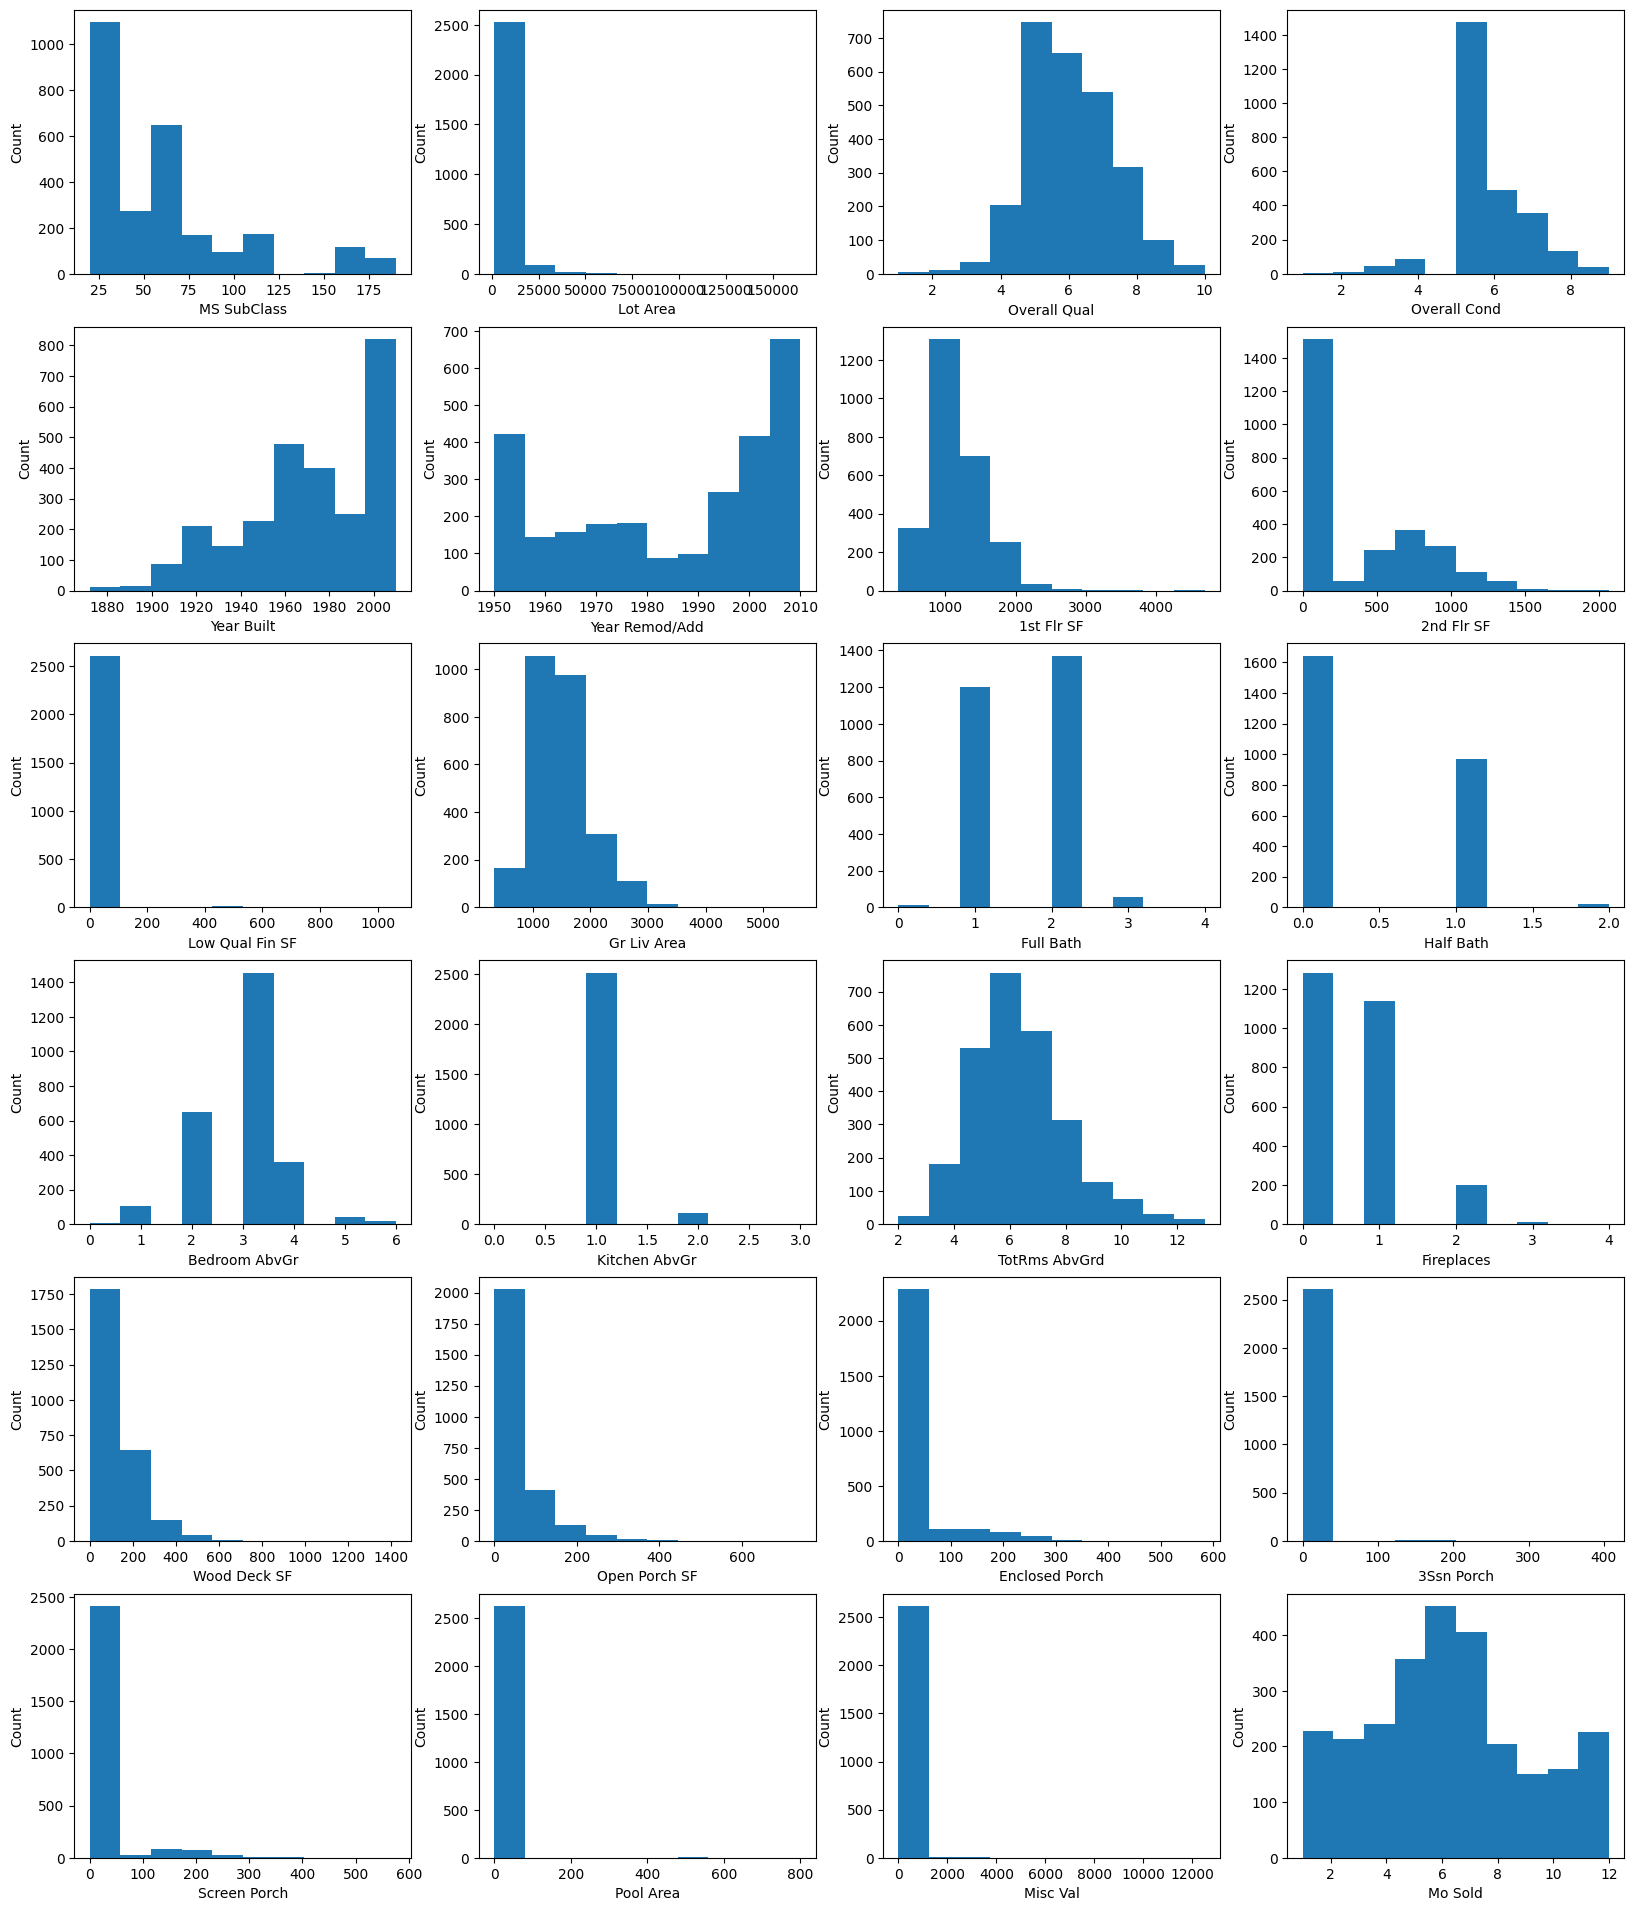

In [489]:
# Let's plot mpg and all of our predictors
subplots_per_row = 4
total_subplots = len(df.columns)
row_count = total_subplots // subplots_per_row
fig, subplots = plt.subplots(row_count,subplots_per_row, figsize = (20,4*row_count)) # Creating 2x4 subplots because we have 8 columns in our data
column_names = df.columns

subplots = subplots.flatten()[:len(column_names)]  # flatten and slice axs
for n, subplot in enumerate(subplots):             # Loop through axs
  subplot.hist(df[column_names[n]])
  subplot.set_xlabel(column_names[n])
  subplot.set_ylabel('Count')

### What do we notice?

- For int columns, some features are positively skewed, others negatively skewed, and a couple are evenly distributed
- Lots of positively skewed features (almost look categorical)
- Some features appear categorical (only a few unique values per feature)
- Perhaps some outliers (see positively skewed point above)

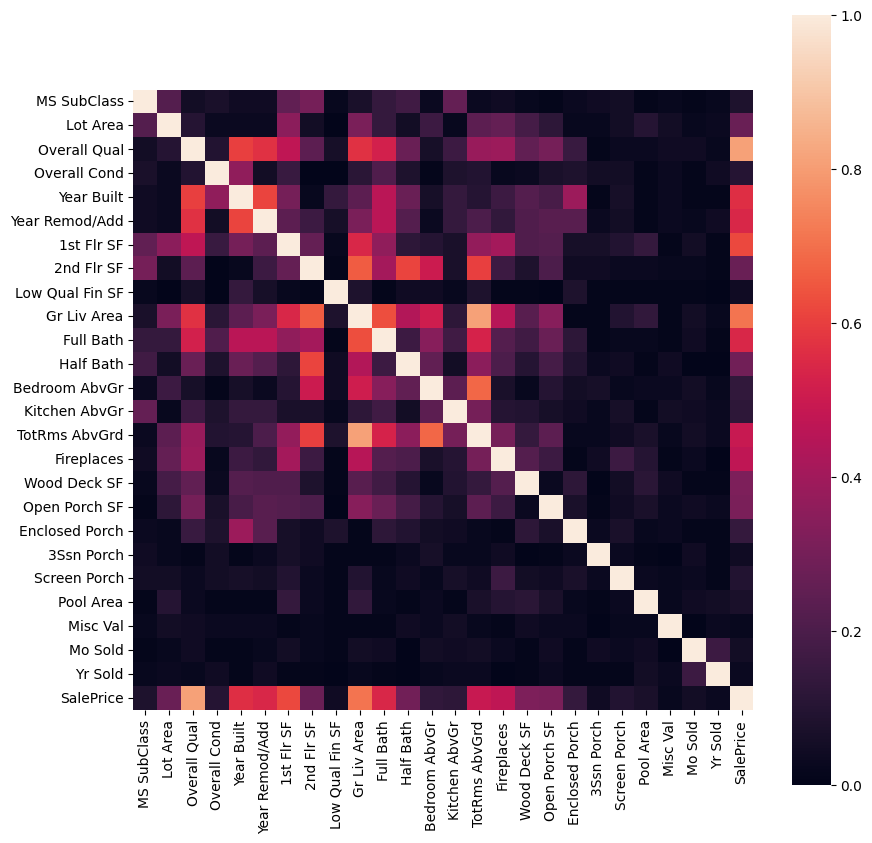

In [494]:
# Correlation plot - target and features
plt.figure(figsize=(10,10))
correlation_matrix = df.corr().abs().round(2)
sns.heatmap(data=correlation_matrix, annot=False, vmin=0, vmax=1, square=True) ;



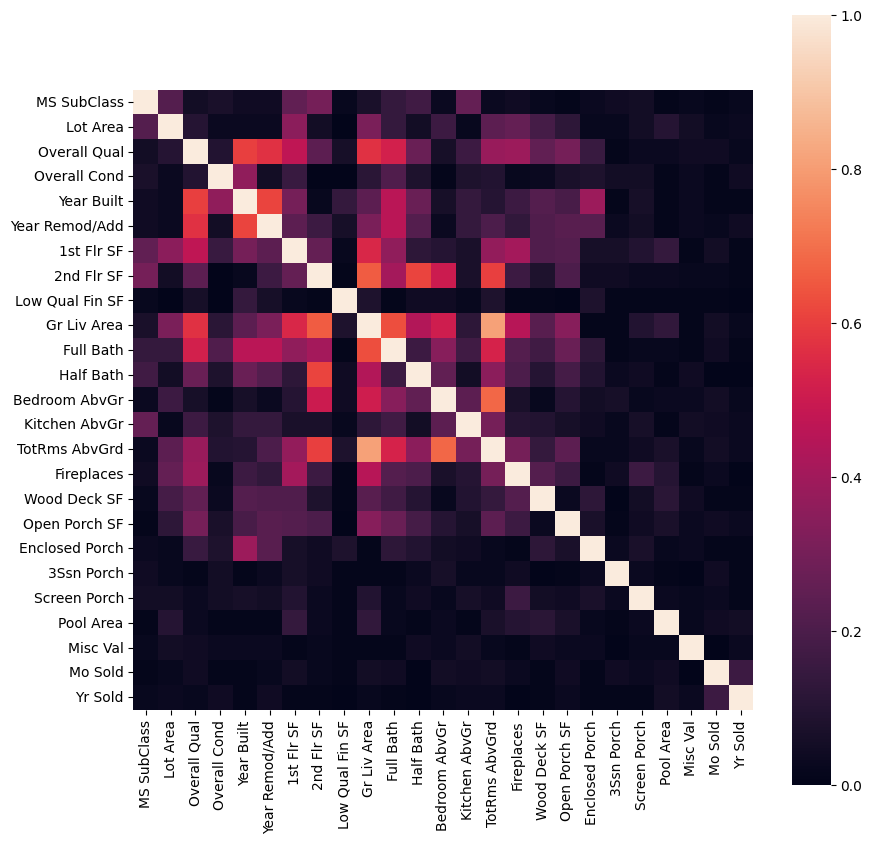

In [495]:
# Correlation plot - features only
plt.figure(figsize=(10,10))
correlation_matrix = df.drop( columns = [target_col] ).corr().abs().round(2)
sns.heatmap(data=correlation_matrix, annot=False, vmin=0, vmax=1, square=True) ;



In [496]:
correlation_matrix = df.corr().round(2)
correlation_matrix[target_col].abs().sort_values(ascending=False)

,SalePrice
SalePrice,1.00
Overall Qual,0.81
Gr Liv Area,0.71
1st Flr SF,0.62
Year Built,0.56
Year Remod/Add,0.54
Full Bath,0.54
TotRms AbvGrd,0.49
Fireplaces,0.47
Wood Deck SF,0.32


<Axes: >

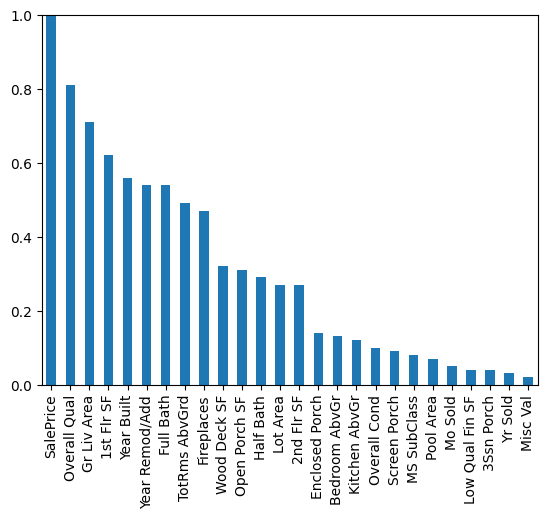

In [497]:
correlation_matrix = df.corr().round(2)
correlation_matrix[target_col].abs().sort_values(ascending=False).plot( kind="bar", ylim = [0,1])

In [498]:
corrs = df.corr().round(2).unstack().abs()
corrs.reset_index()

,level_0,level_1,0
0,MS SubClass,MS SubClass,1.00
1,MS SubClass,Lot Area,0.22
2,MS SubClass,Overall Qual,0.05
3,MS SubClass,Overall Cond,0.07
4,MS SubClass,Year Built,0.04
...,...,...,...
671,SalePrice,Pool Area,0.07
672,SalePrice,Misc Val,0.02
673,SalePrice,Mo Sold,0.05
674,SalePrice,Yr Sold,0.03


In [499]:
corrs = corrs[corrs < 1]
corrs.reset_index()

,level_0,level_1,0
0,MS SubClass,Lot Area,0.22
1,MS SubClass,Overall Qual,0.05
2,MS SubClass,Overall Cond,0.07
3,MS SubClass,Year Built,0.04
4,MS SubClass,Year Remod/Add,0.04
...,...,...,...
645,SalePrice,Screen Porch,0.09
646,SalePrice,Pool Area,0.07
647,SalePrice,Misc Val,0.02
648,SalePrice,Mo Sold,0.05


In [500]:
corrs.sort_values(ascending = False).reset_index()

,level_0,level_1,0
0,TotRms AbvGrd,Gr Liv Area,0.81
1,SalePrice,Overall Qual,0.81
2,Gr Liv Area,TotRms AbvGrd,0.81
3,Overall Qual,SalePrice,0.81
4,Gr Liv Area,SalePrice,0.71
...,...,...,...
645,Misc Val,3Ssn Porch,0.00
646,Misc Val,Mo Sold,0.00
647,Mo Sold,Half Bath,0.00
648,Yr Sold,Low Qual Fin SF,0.00


In [501]:
corrs.sort_values(ascending = False)[::2].reset_index()

,level_0,level_1,0
0,TotRms AbvGrd,Gr Liv Area,0.81
1,Gr Liv Area,TotRms AbvGrd,0.81
2,Gr Liv Area,SalePrice,0.71
3,Bedroom AbvGr,TotRms AbvGrd,0.68
4,Gr Liv Area,2nd Flr SF,0.66
...,...,...,...
320,2nd Flr SF,Overall Cond,0.00
321,Half Bath,Yr Sold,0.00
322,Low Qual Fin SF,Overall Cond,0.00
323,Misc Val,Mo Sold,0.00


### What do we notice?

- SalePrice correlated with General living area, first floor sf, year built, and overall quality
- lattice pattern: typically, if a feature doesn't correlate with other features, it also doesn't correlate with the target

In [502]:
df.size

68562

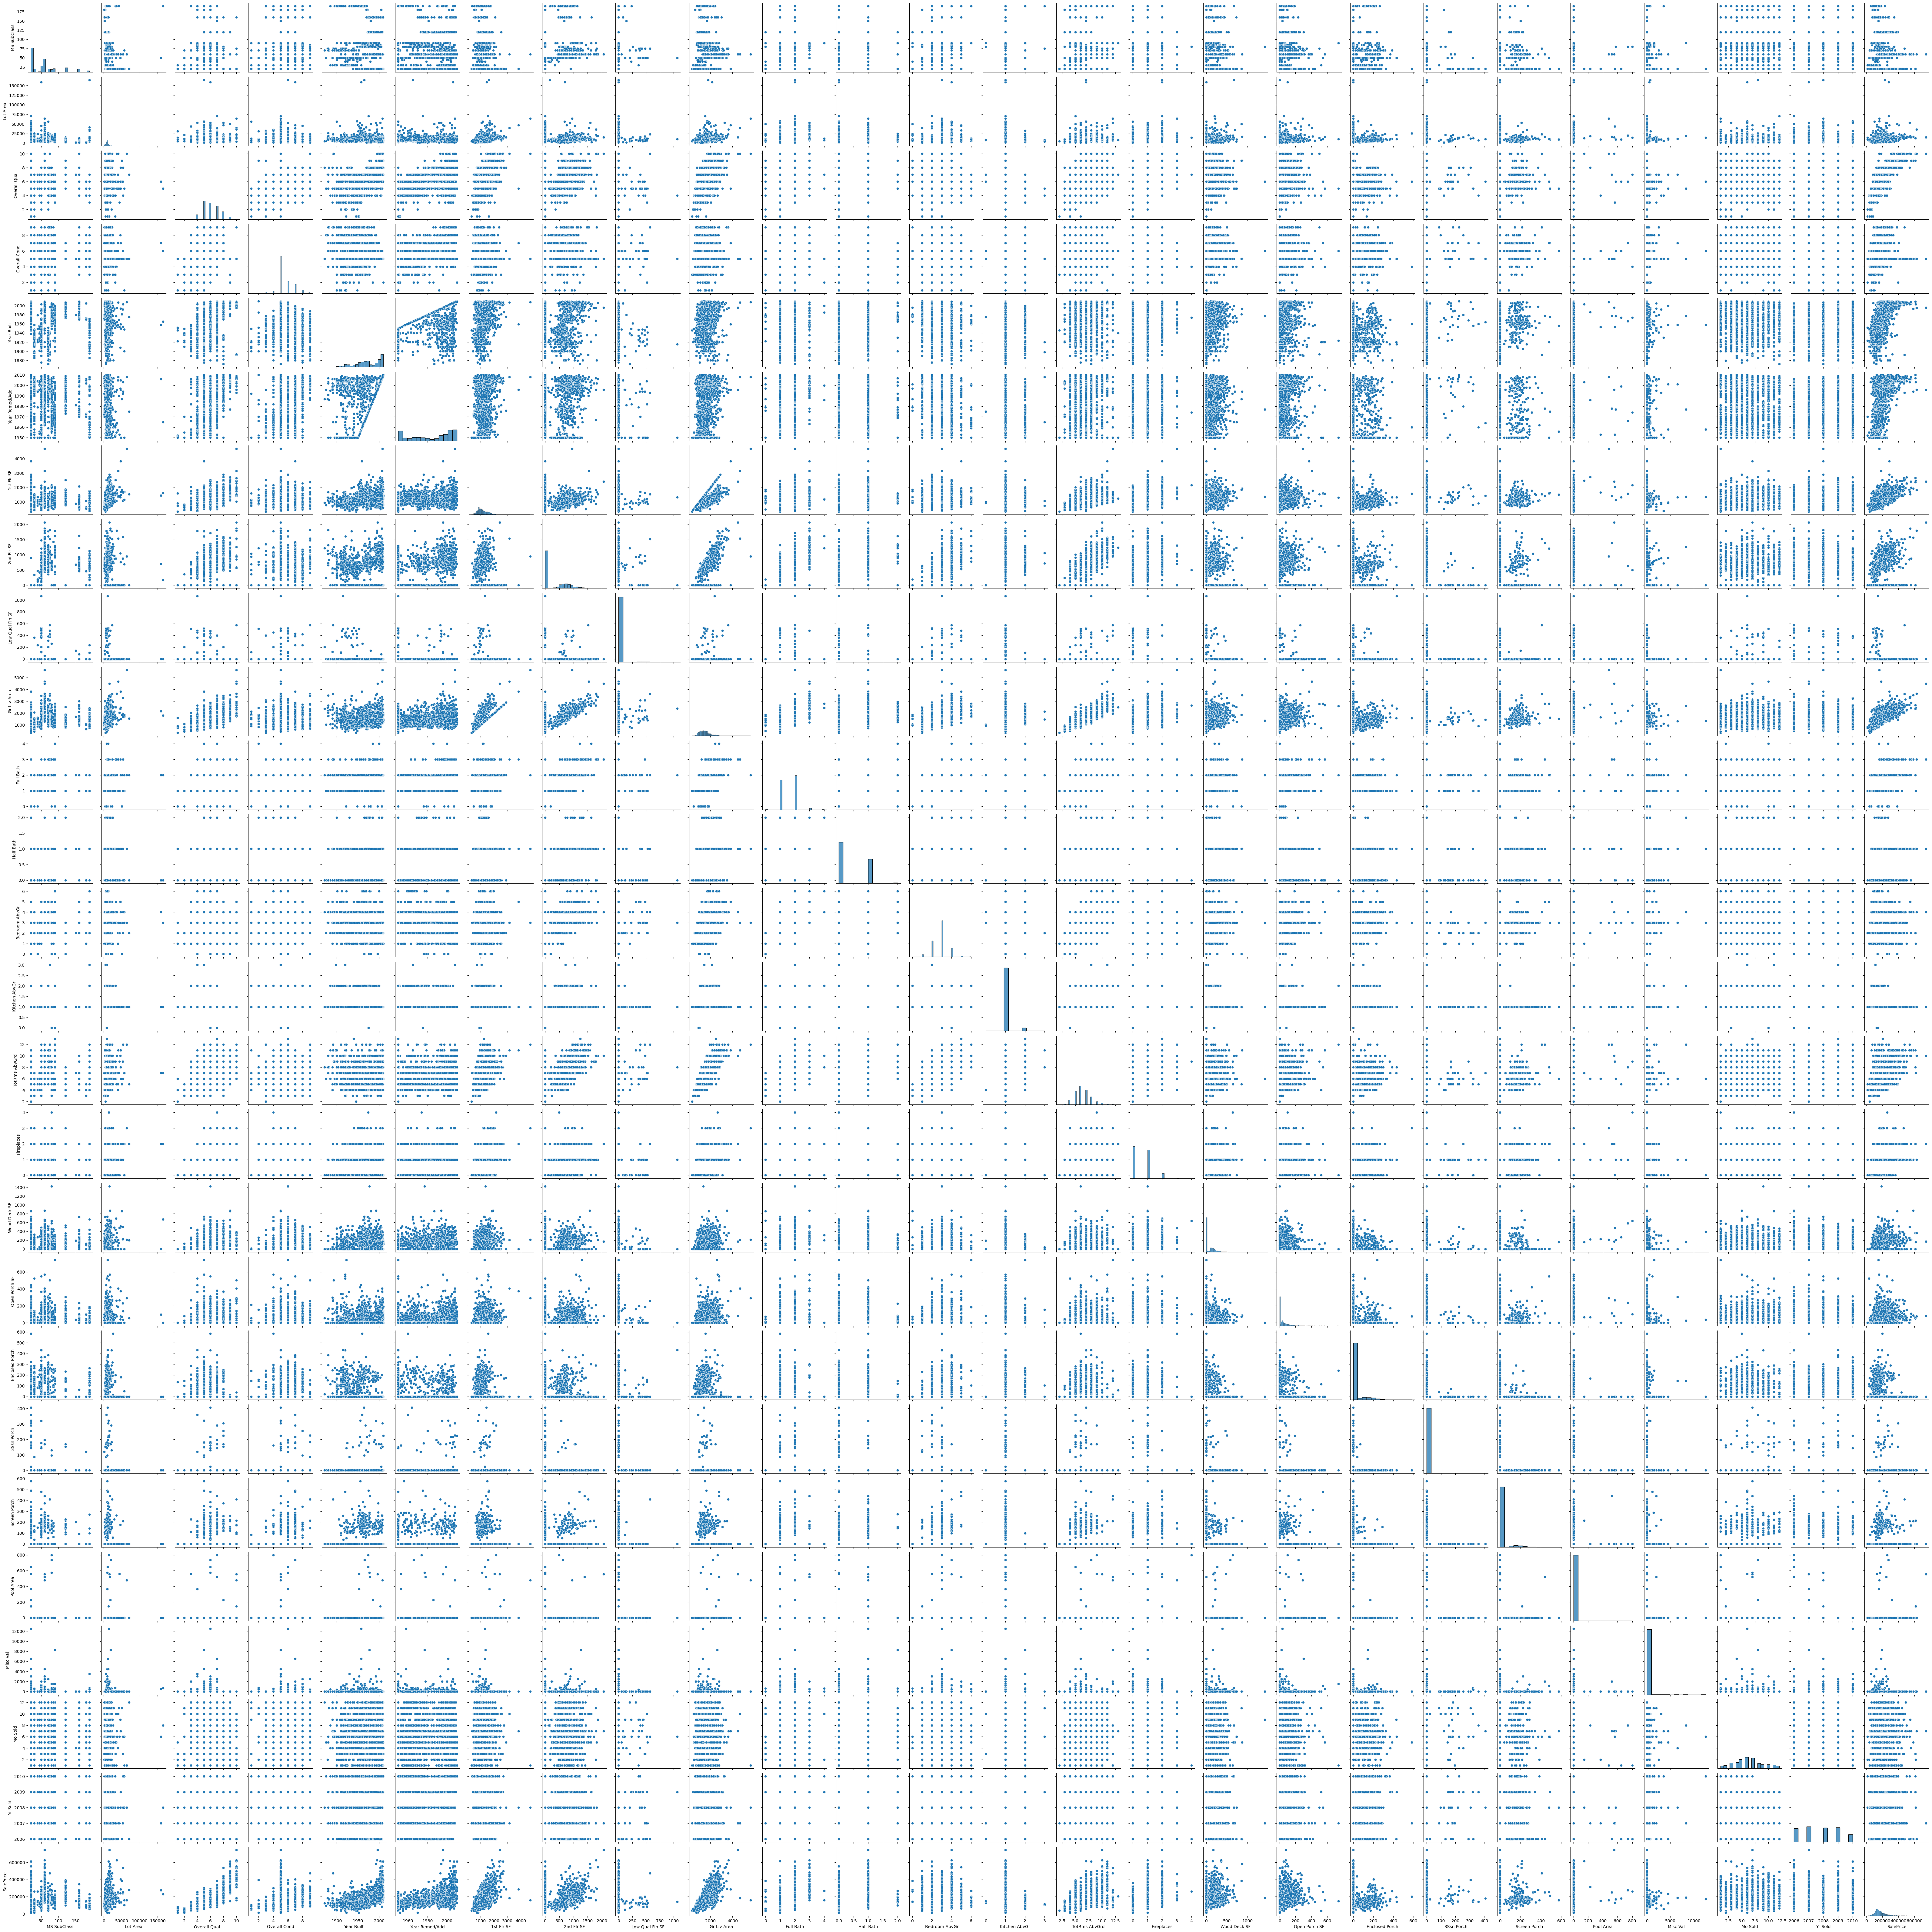

In [503]:
# Let's plot a pairplot
sns.pairplot(df) ;



### What do we notice?

- Not as many non-categorical scatter plots
- some linear-looking trends, including general living area and overall quality (i.e., they highly correlate with the target, and have linear-looking plot clustering)

## Processing



## Data Visualization/Communication of Results
